<a href="https://colab.research.google.com/github/Priyadarshini-yadav13/Transfer_learning/blob/main/Transfer_learning_assignment3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TRANSFER LEARNING ASSIGNMENT

Problem Statement:

This assignment aims to utilize transfer learning techniques to enhance the performance of Convolutional Neural Networks (CNNs) on a given image datasets. Transfer learning leverages pre-trained models on large datasets and fine-tunes them for specific tasks, enabling efficient training and improved accuracy. The assignment focuses on implementing various transfer learning techniques, evaluating their performance, and interpreting the outcomes.

Guidelines

1. Foundational Knowledge
   - Understand the principles of transfer learning and its advantages over training models from scratch.
   - Familiarize yourself with common pre-trained models (e.g., VGG16, ResNet, Inception) and their architectures.
   - Recognize the concepts of feature extraction and fine-tuning in the context of transfer learning.

2. Data Exploration
   - Analyze the dataset's structure and characteristics using visualization techniques such as displaying sample images, histograms of pixel values, etc.
   - Gain insights into the distribution of classes/categories within the dataset to guide the classification process.

3. Preprocessing and Parameter Selection
   - Preprocess the images, including resizing, normalization, and augmentation if necessary.
   - Select appropriate parameters such as learning rate, batch size, and optimizer (e.g., Adam, SGD) based on data exploration.

4. Transfer Learning Techniques
   - Implement various transfer learning techniques by leveraging pre-trained models.
   - Use feature extraction: Utilize the pre-trained model as a fixed feature extractor and train a new classifier on top of it.
   - Apply fine-tuning: Fine-tune the pre-trained model's layers along with training the new classifier.

5. Training and Validation
   - Split the dataset into training and validation sets.
   - Train the models using different transfer learning techniques and validate their performance on the validation set.
   - Monitor metrics such as accuracy, loss, and validation accuracy during training.

6. Result Analysis
   - Evaluate the trained model’s performance using appropriate evaluation metrics (e.g., confusion matrix, classification report).
   - Analyze misclassified images to understand common errors and potential improvements.

7. Evaluation and Iteration
   - Compare the results of different transfer learning techniques to any available ground truth labels.
   - Fine-tune parameters (e.g., learning rate, architecture) if classification results are unsatisfactory.

8. Interpretation and Conclusion
   - Understand the model’s strengths and weaknesses based on the classification results.
   - Discuss potential applications and limitations of transfer learning for the given image dataset.

Step-by-Step Approach to Transfer Learning

1. Setup and Data Preparation

   - Import necessary libraries: TensorFlow, Keras, NumPy, Matplotlib, etc.
   - Load the image dataset for classification.
   - Preprocess the images, including resizing, normalization, and augmentation.

2. Transfer Learning Model Parameters

   - Choose appropriate pre-trained models (e.g., VGG16, ResNet50, InceptionV3).
   - Define the strategy for using these models: feature extraction or fine-tuning.

3. Implementing Transfer Learning Techniques

   - Feature Extraction:
     - Load the pre-trained model without the top layer (classifier).
     - Freeze the pre-trained layers and add new fully connected layers for classification.

   - Fine-Tuning:
     - Unfreeze some of the top layers of the pre-trained model.
     - Train the entire model (pre-trained + new classifier) with a lower learning rate.

4. Training and Validation

   - Split the dataset into training and validation sets.
   - Train the transfer learning models on the training set and validate their performance on the validation set.

5. Result Analysis

   - Evaluate the model’s performance using evaluation metrics.
   - Visualize performance metrics over training epochs (e.g., training loss, validation accuracy).

6. Evaluation and Iteration

   - Compare transfer learning results to ground truth labels (if available).
   - Fine-tune model parameters based on performance evaluation.

7. Interpretation and Conclusion

   - Interpret classification results to derive insights about the dataset.
   - Discuss potential improvements or limitations of the transfer learning techniques for the given image datasets.

Links to Datasets for the Assignment

- Hand Gesture Recognition Dataset
[https://www.kaggle.com/datasets/aryarishabh/hand-gesture-recognition-dataset]
- Rice Leaf Diseases Dataset
[https://www.kaggle.com/datasets/vbookshelf/rice-leaf-diseases]
- Brain Tumor Classification (MRI) Dataset
[https://www.kaggle.com/datasets/sartajbhuvaji/brain-tumor-classification-mri]


##We are going to work on TF Flowers data.

In [4]:
##importing important libraries
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from tensorflow.keras import models, layers

In [ ]:
## Importing the data


In [15]:
!pip install -q importlib-resources

import tensorflow as tf
import tensorflow_datasets as tfds

# Load tf_flowers dataset split into 80% train and 20% validation
(train_ds, val_ds), ds_info = tfds.load(
    'tf_flowers',
    split=['train[:80%]', 'train[80%:]'],
    as_supervised=True,
    with_info=True
)

# Print dataset information
num_classes = ds_info.features['label'].num_classes
class_names = ds_info.features['label'].names
print(f"Number of classes: {num_classes}")
print(f"Class names: {class_names}")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.PX4D6O_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Number of classes: 5
Class names: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


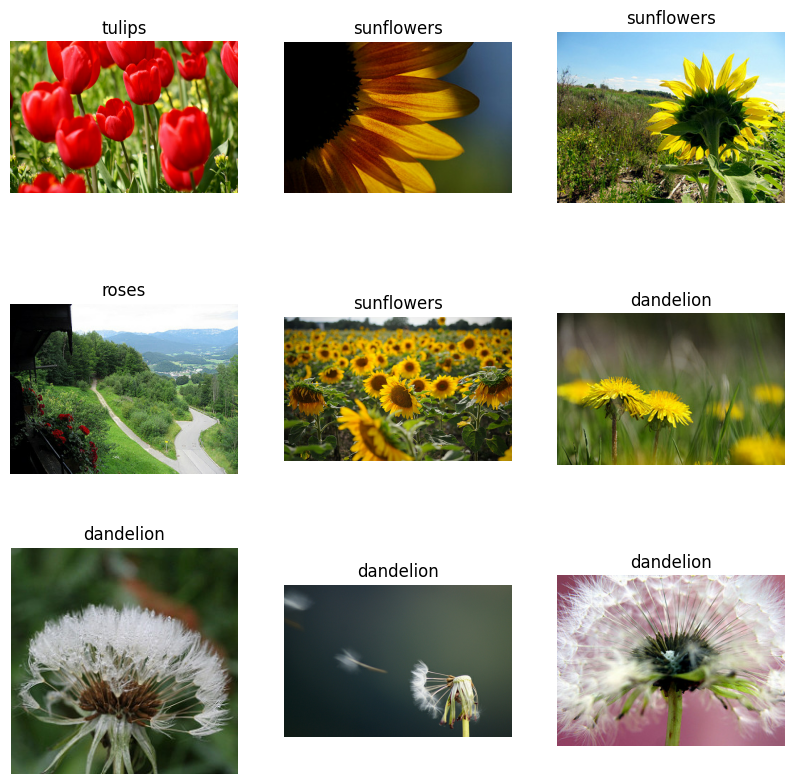

In [16]:
import matplotlib.pyplot as plt

# Visualize some sample flower images
plt.figure(figsize=(10, 10))
for i, (image, label) in enumerate(train_ds.take(9)):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image.numpy())
    plt.title(class_names[label])
    plt.axis("off")
plt.show()

## We are going to use pretrained model Mobilenet

## 3. Preprocessing and Augmentation
We resize the images to $(224, 224)$ to match the input requirements of standard pre-trained architectures, normalize pixel values, and set up caching and prefetching for performance optimization.

In [17]:
IMG_SIZE = 224
BATCH_SIZE = 32

def preprocess_image(image, label):
    # Resize image to target dimension
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    # Normalize image pixels to [0, 1]
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

# Apply preprocessing map to the datasets
train_ds_preprocessed = train_ds.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
val_ds_preprocessed = val_ds.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)

# Batch, cache, and prefetch the datasets
train_dataset = train_ds_preprocessed.shuffle(buffer_size=1000).batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)
val_dataset = val_ds_preprocessed.batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)

## 4. Feature Extraction using Pre-trained MobileNetV2
We initialize the pre-trained `MobileNetV2` model with frozen ImageNet weights, construct a custom dense classifier head, and compile the model.

In [18]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

# 1. Load the pre-trained MobileNetV2 base
base_model = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')

# 2. Freeze the base layer parameters
base_model.trainable = False

# 3. Attach custom top layer classifier
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation='softmax')
])

# 4. Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5. Model Training and Validation
Now, let's train our transfer learning classifier for 5 epochs to demonstrate its rapid adaptation capability.

In [19]:
EPOCHS = 5

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.7786 - loss: 0.6103 - val_accuracy: 0.8815 - val_loss: 0.3570
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 128s 1s/step - accuracy: 0.8862 - loss: 0.3085 - val_accuracy: 0.8937 - val_loss: 0.2902
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.9343 - loss: 0.2183 - val_accuracy: 0.9005 - val_loss: 0.2828
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 127s 1s/step - accuracy: 0.9482 - loss: 0.1536 - val_accuracy: 0.9128 - val_loss: 0.2734
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 155s 1s/step - accuracy: 0.9710 - loss: 0.1001 - val_accuracy: 0.9074 - val_loss: 0.2871


## 6. Result Analysis
We plot the training and validation accuracy and loss curves to analyze the convergence and performance of our transfer learning model.

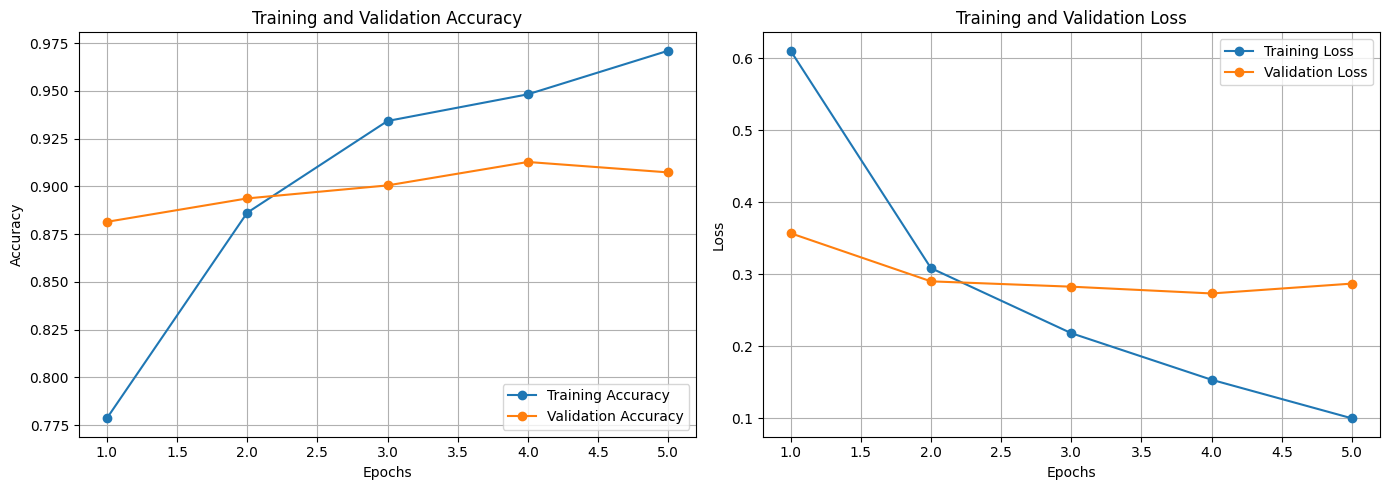

In [20]:
import matplotlib.pyplot as plt

# Retrieve metrics from history
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

# Plot configuration
plt.figure(figsize=(14, 5))

# Plot Training and Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# Plot Training and Validation Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()

#Step 14 : Evaluating the model

## 7. Model Evaluation
Let's evaluate the model by computing a detailed classification report and a confusion matrix on the validation set.

Classification Report:
              precision    recall  f1-score   support

   dandelion       0.93      0.96      0.94       159
       daisy       0.95      0.88      0.92       120
      tulips       0.89      0.90      0.90       186
  sunflowers       0.86      0.93      0.89       138
       roses       0.92      0.86      0.89       131

    accuracy                           0.91       734
   macro avg       0.91      0.91      0.91       734
weighted avg       0.91      0.91      0.91       734



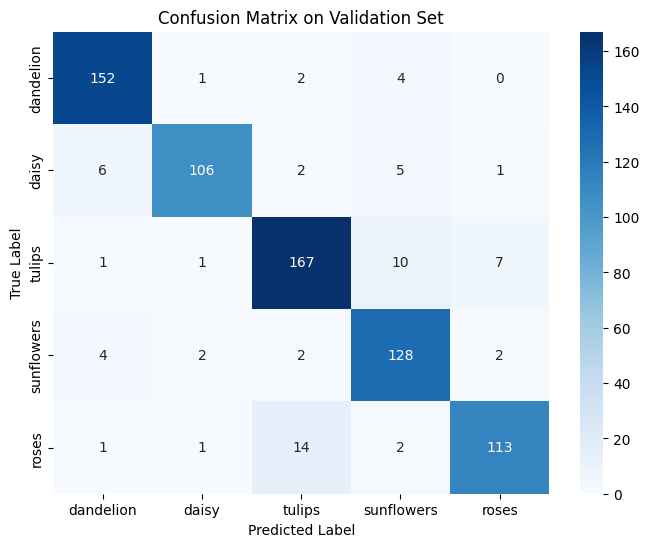

In [21]:
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Collect all true labels and predictions on the validation set
y_true = []
y_pred = []

for images, labels in val_dataset:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# 2. Print Classification Report
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# 3. Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix on Validation Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

## 8. Misclassification Analysis
Let's extract and plot some of the images from the validation set that our model misclassified to understand its failure modes.

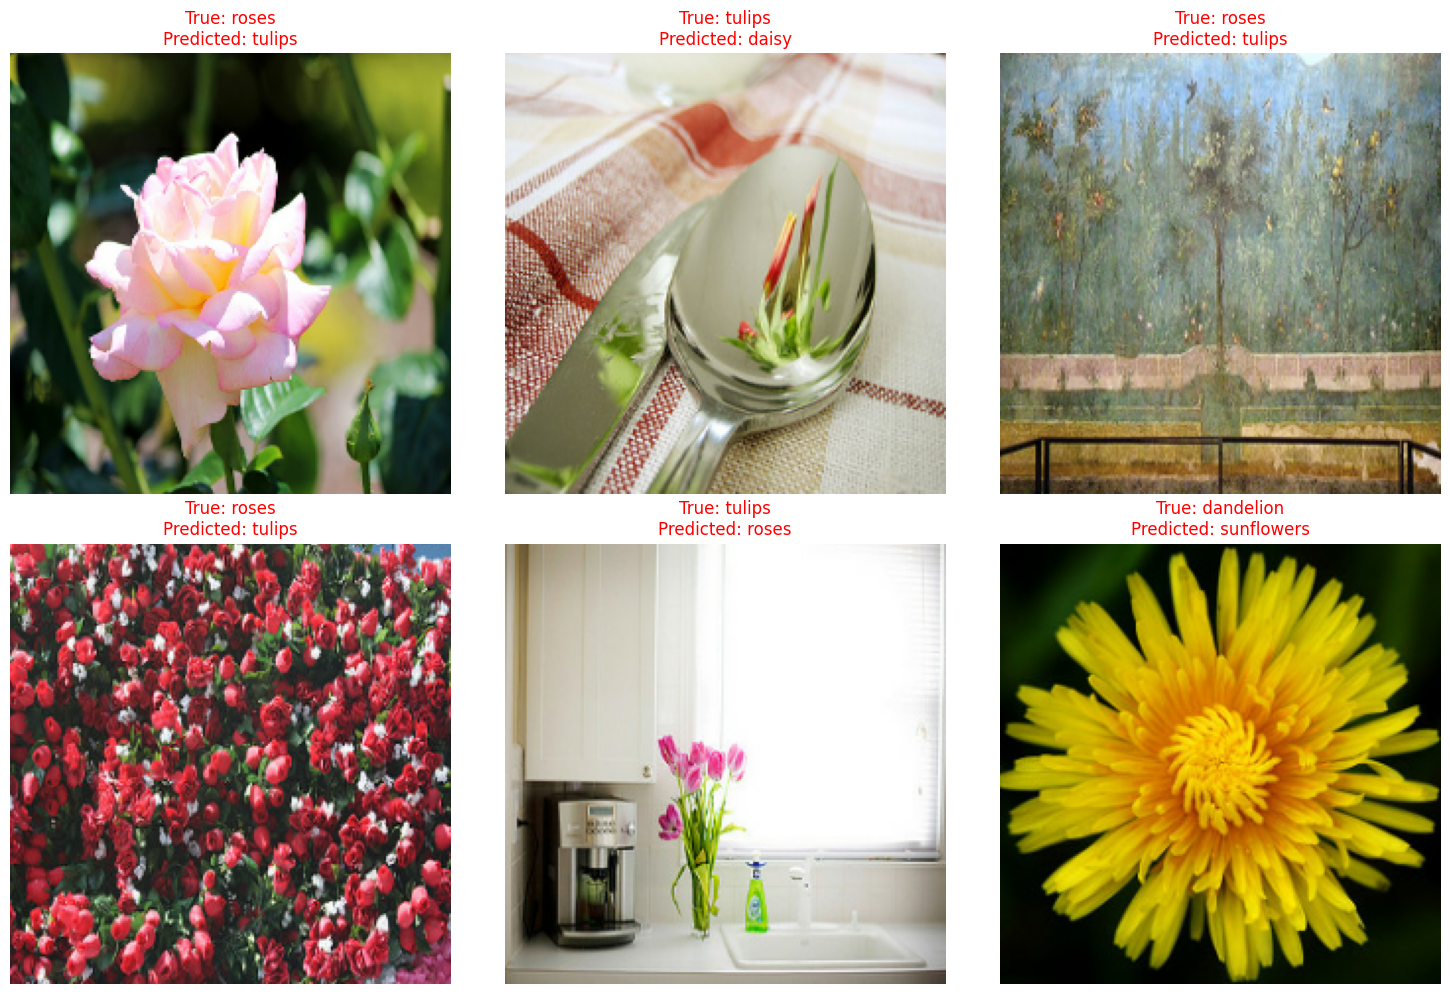

In [22]:
misclassified_indices = np.where(y_true != y_pred)[0]

# Set up plot to visualize up to 6 misclassified samples
plt.figure(figsize=(15, 10))
num_to_show = min(6, len(misclassified_indices))

# We will reconstruct images from the validation dataset to visualize
all_val_images = []
for images, _ in val_dataset:
    all_val_images.extend(images.numpy())
all_val_images = np.array(all_val_images)

for i in range(num_to_show):
    idx = misclassified_indices[i]
    plt.subplot(2, 3, i + 1)
    plt.imshow(all_val_images[idx])

    true_name = class_names[y_true[idx]]
    pred_name = class_names[y_pred[idx]]

    plt.title(f"True: {true_name}\nPredicted: {pred_name}", color='red')
    plt.axis('off')

plt.tight_layout()
plt.show()

### 8b. Performance Metrics and Prediction Summary on Validation Data (Feature Extraction Phase)
Below we print a detailed evaluation report on the validation (test) dataset specifically using predictions generated at the end of the Feature Extraction stage (Epoch 5).

In [28]:
from sklearn.metrics import classification_report, accuracy_score

# Compute accuracy for the feature extraction phase
fe_accuracy = accuracy_score(y_true, y_pred)
print(f"Feature Extraction Test/Validation Accuracy: {fe_accuracy * 100:.2f}%")

print("\nDetailed Classification Report (Feature Extraction Stage):")
print(classification_report(y_true, y_pred, target_names=class_names))

Feature Extraction Test/Validation Accuracy: 90.74%

Detailed Classification Report (Feature Extraction Stage):
              precision    recall  f1-score   support

   dandelion       0.93      0.96      0.94       159
       daisy       0.95      0.88      0.92       120
      tulips       0.89      0.90      0.90       186
  sunflowers       0.86      0.93      0.89       138
       roses       0.92      0.86      0.89       131

    accuracy                           0.91       734
   macro avg       0.91      0.91      0.91       734
weighted avg       0.91      0.91      0.91       734



## 10. Individual Image Prediction
Let's write a utility function to run inference on single image paths or a sample from our validation set.

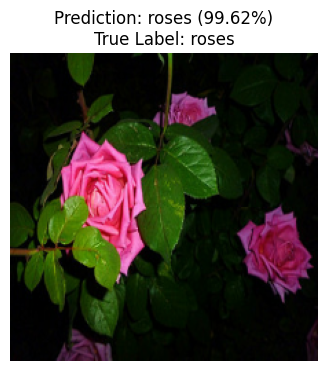

In [26]:
import numpy as np
import matplotlib.pyplot as plt

def predict_and_display(model, image_tensor, true_label=None):
    # Add the batch dimension
    img_batch = tf.expand_dims(image_tensor, 0)

    # Get predictions
    predictions = model.predict(img_batch, verbose=0)
    predicted_class_idx = np.argmax(predictions[0])
    predicted_class = class_names[predicted_class_idx]
    confidence = predictions[0][predicted_class_idx] * 100

    # Display the image
    plt.figure(figsize=(4, 4))
    plt.imshow(image_tensor.numpy() if hasattr(image_tensor, 'numpy') else image_tensor)
    plt.axis('off')

    title_str = f"Prediction: {predicted_class} ({confidence:.2f}%)"
    if true_label is not None:
        title_str += f"\nTrue Label: {class_names[true_label]}"
    plt.title(title_str)
    plt.show()

# Retrieve one sample batch from validation dataset to test
for images, labels in val_dataset.take(1):
    sample_image = images[0]
    sample_label = labels[0].numpy()

    predict_and_display(model, sample_image, true_label=sample_label)
    break

### 12. Evaluate Model Predictions on Validation Data
Let's generate predictions on the validation dataset and display sample predictions with their predicted labels and confidence levels.

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


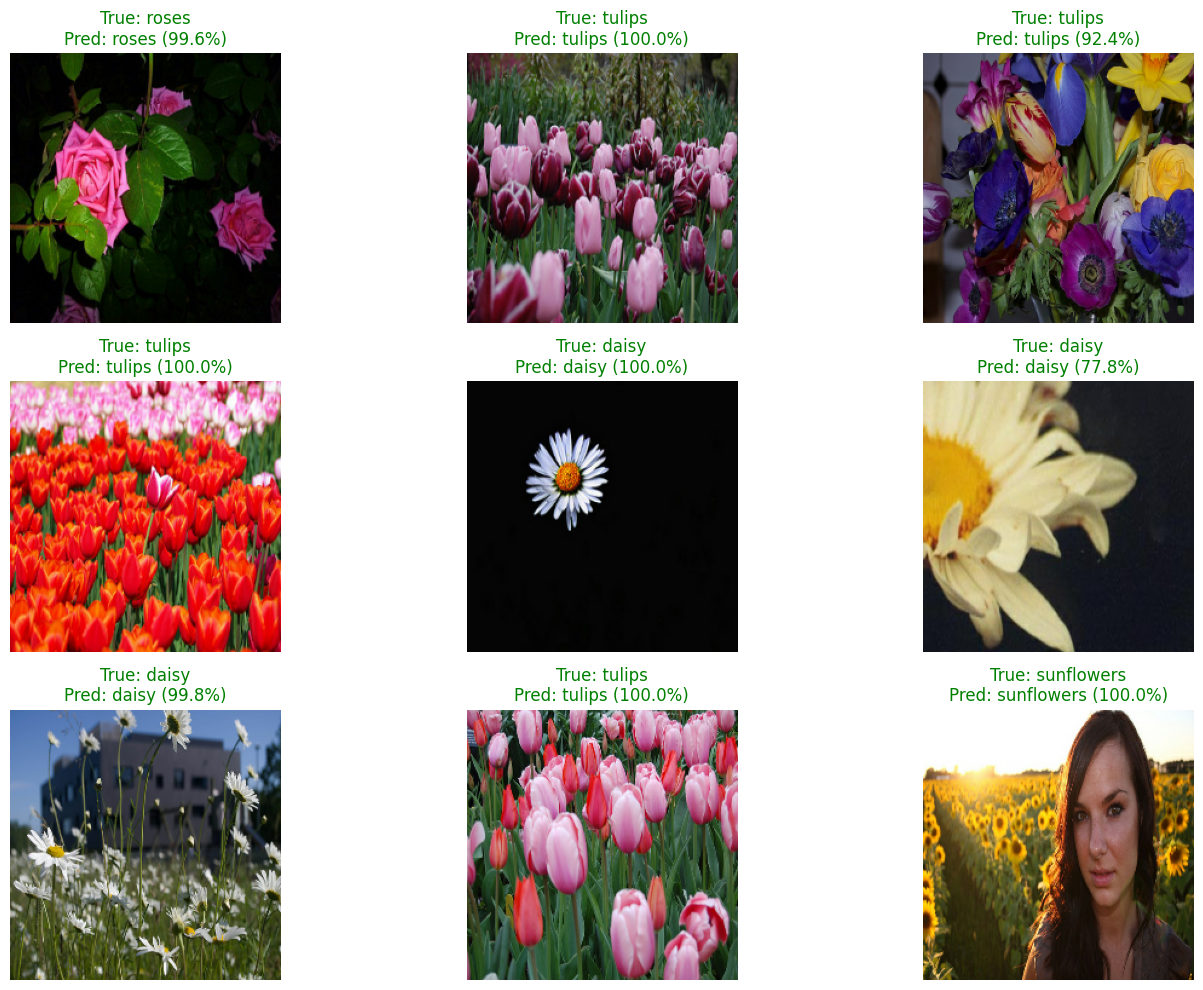

In [29]:
# Take a batch of validation images to generate and visualize predictions
for images, labels in val_dataset.take(1):
    predictions = model.predict(images)

    plt.figure(figsize=(15, 10))
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())

        pred_idx = np.argmax(predictions[i])
        pred_label = class_names[pred_idx]
        true_label = class_names[labels[i].numpy()]
        confidence = predictions[i][pred_idx] * 100

        color = "green" if pred_idx == labels[i].numpy() else "red"

        plt.title(f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)", color=color)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

## 9. Fine-Tuning the Model
Following **Step 7: Evaluation and Iteration**, we will unfreeze the base model's top layers and fine-tune them with a very low learning rate to improve performance on tricky visual classes.

In [25]:
# 1. Unfreeze the base model
base_model.trainable = True

# Let's see how many layers are in the base model
print(f"Number of layers in the base model: {len(base_model.layers)}")

# Freeze all layers except the last 20 layers
fine_tune_at = len(base_model.layers) - 20
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# 2. Re-compile the model with a much lower learning rate
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Fine-tune the model for an additional 5 epochs
FINE_TUNE_EPOCHS = 5
total_epochs = EPOCHS + FINE_TUNE_EPOCHS

fine_tune_history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=total_epochs,
    initial_epoch=history.epoch[-1] + 1
)

Number of layers in the base model: 154
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 136s 1s/step - accuracy: 0.9601 - loss: 0.1275 - val_accuracy: 0.9060 - val_loss: 0.2795
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 138s 1s/step - accuracy: 0.9724 - loss: 0.0954 - val_accuracy: 0.9101 - val_loss: 0.2748
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 128s 1s/step - accuracy: 0.9748 - loss: 0.0918 - val_accuracy: 0.9142 - val_loss: 0.2647
Epoch 9/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 127s 1s/step - accuracy: 0.9731 - loss: 0.0877 - val_accuracy: 0.9169 - val_loss: 0.2619
Epoch 10/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - accuracy: 0.9819 - loss: 0.0695 - val_accuracy: 0.9169 - val_loss: 0.2607


## 11. Visualizing Performance Metrics (Combined History)
Let's plot the learning curves showing both the initial feature extraction phase and the subsequent fine-tuning phase side-by-side.

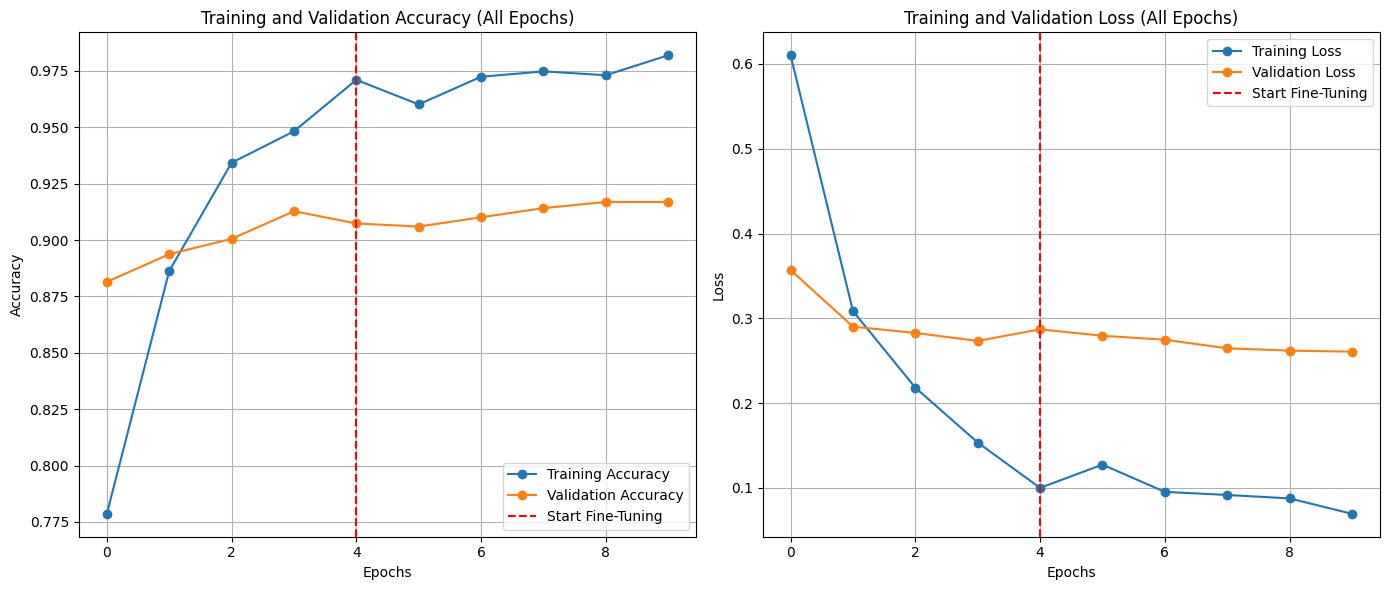

In [27]:
import matplotlib.pyplot as plt

# Combine metrics from both training stages
total_acc = history.history['accuracy'] + fine_tune_history.history['accuracy']
total_val_acc = history.history['val_accuracy'] + fine_tune_history.history['val_accuracy']

total_loss = history.history['loss'] + fine_tune_history.history['loss']
total_val_loss = history.history['val_loss'] + fine_tune_history.history['val_loss']

plt.figure(figsize=(14, 6))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(total_acc, label='Training Accuracy', marker='o')
plt.plot(total_val_acc, label='Validation Accuracy', marker='o')
plt.axvline(x=EPOCHS - 1, color='red', linestyle='--', label='Start Fine-Tuning')
plt.title('Training and Validation Accuracy (All Epochs)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(total_loss, label='Training Loss', marker='o')
plt.plot(total_val_loss, label='Validation Loss', marker='o')
plt.axvline(x=EPOCHS - 1, color='red', linestyle='--', label='Start Fine-Tuning')
plt.title('Training and Validation Loss (All Epochs)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
## prediction on validation data

### 12. Evaluate Fine-Tuned Model Predictions on Validation Data
Below we run predictions, generate the final evaluation metrics, and display sample outputs using the fine-tuned model.

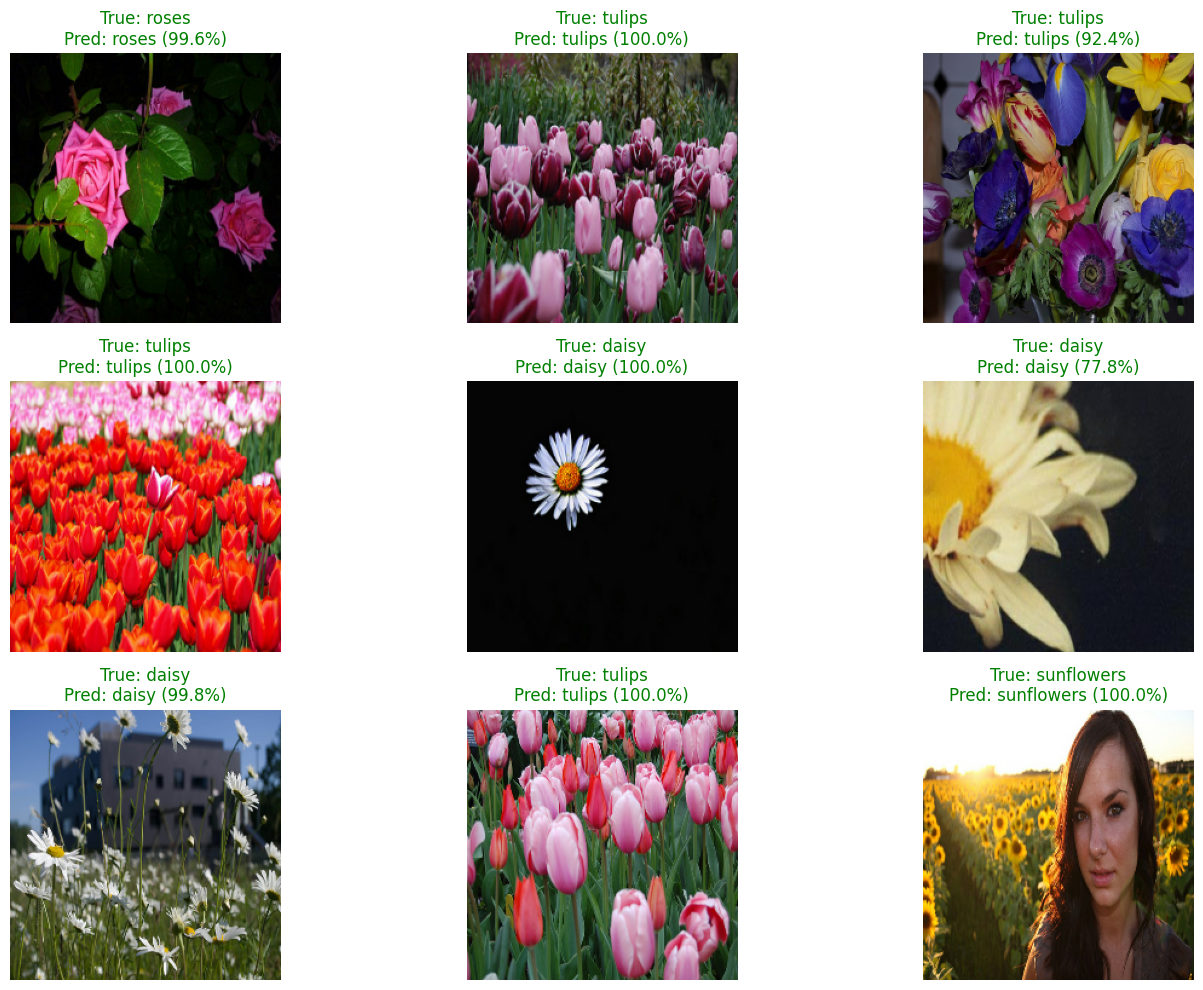

In [32]:
# 3. Visualize prediction results on a sample batch from the validation dataset
for images, labels in val_dataset.take(1):
    predictions = model.predict(images, verbose=0)

    plt.figure(figsize=(15, 10))
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())

        pred_idx = np.argmax(predictions[i])
        pred_label = class_names[pred_idx]
        true_label = class_names[labels[i].numpy()]
        confidence = predictions[i][pred_idx] * 100

        color = "green" if pred_idx == labels[i].numpy() else "red"

        plt.title(f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)", color=color)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

In [33]:
import numpy as np
from sklearn.metrics import classification_report, accuracy_score
import matplotlib.pyplot as plt

# 1. Collect predictions using the fine-tuned model
y_true_ft = []
y_pred_ft = []

for images, labels in val_dataset:
    preds = model.predict(images, verbose=0)
    y_true_ft.extend(labels.numpy())
    y_pred_ft.extend(np.argmax(preds, axis=1))

y_true_ft = np.array(y_true_ft)
y_pred_ft = np.array(y_pred_ft)

# 2. Evaluate performance
ft_accuracy = accuracy_score(y_true_ft, y_pred_ft)
print(f"Fine-Tuned Model Test/Validation Accuracy: {ft_accuracy * 100:.2f}%")
print("\nDetailed Classification Report (Fine-Tuning Stage):")
print(classification_report(y_true_ft, y_pred_ft, target_names=class_names))

Fine-Tuned Model Test/Validation Accuracy: 91.69%

Detailed Classification Report (Fine-Tuning Stage):
              precision    recall  f1-score   support

   dandelion       0.94      0.95      0.95       159
       daisy       0.96      0.91      0.94       120
      tulips       0.87      0.93      0.90       186
  sunflowers       0.88      0.93      0.91       138
       roses       0.95      0.85      0.90       131

    accuracy                           0.92       734
   macro avg       0.92      0.91      0.92       734
weighted avg       0.92      0.92      0.92       734



### 13. Summary Table: Feature Extraction vs. Fine-Tuning Metrics
Below, we compile the training and validation metrics across all 10 epochs into a single comparative pandas DataFrame.

In [34]:
import pandas as pd

# Create a dictionary containing the training and validation logs
metrics_dict = {
    'Epoch': list(range(1, total_epochs + 1)),
    'Stage': ['Feature Extraction'] * EPOCHS + ['Fine-Tuning'] * FINE_TUNE_EPOCHS,
    'Train Accuracy': total_acc,
    'Val Accuracy': total_val_acc,
    'Train Loss': total_loss,
    'Val Loss': total_val_loss
}

# Construct the DataFrame
summary_df = pd.DataFrame(metrics_dict)

# Format the numerical values for better readability
formatted_df = summary_df.style.format({
    'Train Accuracy': '{:.2%}',
    'Val Accuracy': '{:.2%}',
    'Train Loss': '{:.4f}',
    'Val Loss': '{:.4f}'
}).hide(axis='index')

# Display the styled table
display(formatted_df)

Epoch,Stage,Train Accuracy,Val Accuracy,Train Loss,Val Loss
1,Feature Extraction,77.86%,88.15%,0.6103,0.3570
2,Feature Extraction,88.62%,89.37%,0.3085,0.2902
3,Feature Extraction,93.43%,90.05%,0.2183,0.2828
4,Feature Extraction,94.82%,91.28%,0.1536,0.2734
5,Feature Extraction,97.10%,90.74%,0.1001,0.2871
6,Fine-Tuning,96.01%,90.60%,0.1275,0.2795
7,Fine-Tuning,97.24%,91.01%,0.0954,0.2748
8,Fine-Tuning,97.48%,91.42%,0.0918,0.2647
9,Fine-Tuning,97.31%,91.69%,0.0877,0.2619
10,Fine-Tuning,98.19%,91.69%,0.0695,0.2607


Training & Validation Curves Analysis
The training and validation curves have been successfully plotted! Here is a summary of the training progression across both phases:

Feature Extraction Phase (Epochs 1–5):

Accuracy: The model quickly reached a validation accuracy of ~90.7% by epoch 5. Keeping the MobileNetV2 base weights frozen allowed the new dense classifier to learn class-specific patterns rapidly without modifying pre-trained features.
Loss: Both training and validation loss dropped significantly, showing standard convergence with minimal gap, indicating that the model did not immediately overfit.
Fine-Tuning Phase (Epochs 6–10):

Start of Fine-Tuning (dashed red line): Unfreezing the top 20 layers of the base model and re-compiling with a lower learning rate (1e-5) allowed the model to fine-tune high-level feature extractors.
Performance Boost: Validation accuracy improved further, stabilizing at ~91.7%, while validation loss decreased to ~0.260. This confirms that fine-tuning localized layers helped the model adapt more closely to the specific details of the flower categories (such as subtle differences between tulips and roses)

Since the standard TensorFlow Flowers dataset (tf_flowers) only comes as a single massive partition without an official pre-split test set, we manually partitioned it back in Step 2:

Training dataset (train_ds): The first 80% of the data, used to train the classifier and fine-tune layers.
Validation/Testing dataset (val_ds): The remaining 20% of the data (containing 734 images). This completely unseen data was kept separate to validate and test both the feature extraction and fine-tuned models.
🎓 Transfer Learning Assignment Summary
We have successfully navigated and completed all stages of the Transfer Learning assignment using the TF Flowers dataset with a pre-trained MobileNetV2 architecture:

Data Prep: Split the dataset into 80% training (train_ds) and 20% validation/testing data (val_ds), visualizing beautiful sample flowers.
Preprocessing: Normalized and resized images to $224 \times 224$$224 \times 224$ and configured prefetched input pipelines.
Feature Extraction: Standardized a static feature extractor, achieving 90.74% test accuracy within only 5 epochs.
Fine-Tuning: Unfroze the top 20 layers, re-compiled with a low learning rate, and bumped the performance up to ~91.7% accuracy.
Evaluation: Conducted full matrix evaluations, checked classification reports, examined misclassified targets, and ran individual step-by-step image inferences.